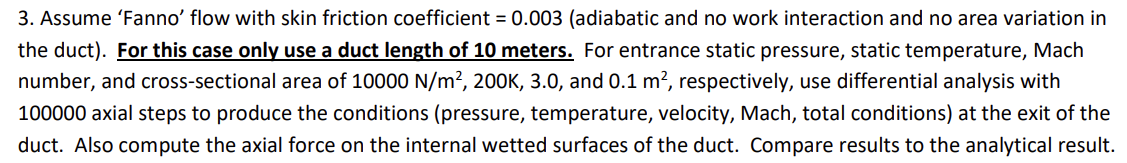

In [10]:
import numpy as np
from quasi_1D import quasi_1D_flow
import matplotlib.pyplot as plt

import scipy as sp


In [11]:
Cp = 1004.5
R = 287
gamma = 1.4

# Numerical

In [12]:
Pi = 10_000
Ti = 200
Mi = 3.0
ui = Mi * np.sqrt(1.4*287*Ti)
Cf = 0.003

L_tube = 10
axial_steps = 100_000

Ai = 0.1
Ae = Ai

xlist = np.linspace(0,L_tube,axial_steps+1)
Af = lambda x: Ai

[uout,Tout,Pout], M, x_break, A_break, Thrust = quasi_1D_flow(inlet = [ui,Ti,Pi], Af = Af,N = axial_steps,Cf=Cf, L = L_tube)



0.0


In [13]:
gamma = 1.4
Tt = Tout*(1+(gamma-1)/2*M**2)
Pt = Pout*(1+(gamma-1)/2*M**2)**(gamma/(gamma-1))


print(f'exit Mach =             {M[-1]}')
print(f'exit Velocity =         {uout[-1]} m/s\n')

print(f'exit Temp =             {Tout[-1]} k')
print(f'exit Total Temp =       {Tt[-1]} k\n')

print(f'exit Pressure =         {Pout[-1]} Pa')
print(f'exit Total Pressure =   {Pt[-1]} Pa\n')

# print(f'exit end area = {A_break}')
print(f'{Thrust =                } N')


exit Mach =             1.6377158220298094
exit Velocity =         626.7325841637186 m/s

exit Temp =             364.4832098030452 k
exit Total Temp =       560.0002491522401 k

exit Pressure =         24728.927993002995 Pa
exit Total Pressure =   111171.3082054583 Pa

Thrust =                -1841.481098883276 N


# Analytical

In [14]:
Tte = Ti*(1+(gamma-1)/2*Mi**2)

fv = lambda M: (gamma+1)/2 * np.log(((1+(gamma-1)/2*M**2))
                                    /(M**2))-1/(M**2)

r = np.sqrt(Ai/np.pi)
c = 2*np.pi*r

fve = (gamma*Cf*(c/Ai)*L_tube) + fv(Mi)
f_0 = lambda M: fv(M) - fve

Me = sp.optimize.fsolve(f_0, 2)[0]

Te = Tte / (1+(gamma-1)/2*Me**2)
ue = Me * np.sqrt(gamma*R*Te)

Pe = Pi * (Mi/Me)* ((1+(gamma-1)/2*Mi**2)/(1+(gamma-1)/2*Me**2))**(1/2)
Pte = Pe*((1+(gamma-1)/2*Me**2)**(gamma/(gamma-1)))

rho0 = Pi/(R*Ti)
rho = Pe / (R*Te)


Thrust_a = (rho*ue**2+Pe)*Ae - (rho0*ui**2+Pi)*Ai




In [15]:
print(f'exit Mach =             {Me}')
print(f'exit Velocity =         {ue} m/s\n')

print(f'exit Temp =             {Te} k')
print(f'exit Total Temp =       {Tte} k\n')

print(f'exit Pressure =         {Pe} Pa')
print(f'exit Total Pressure =   {Pte} Pa\n')

print(f'{Thrust_a =              } N')

exit Mach =             1.6377154759928496
exit Velocity =         626.7323585527697 m/s

exit Temp =             364.4831014150735 k
exit Total Temp =       560.0 k

exit Pressure =         24728.997052612474 Pa
exit Total Pressure =   111171.56126170137 Pa

Thrust_a =              -1841.468798930151 N


# Error

In [16]:
print(f'exit Mach error =           {M[-1]-Me}')
print(f'exit Velocity error =       {uout[-1]-ue} m/s\n')

print(f'exit Temp error =           {Tout[-1]-Te} k')
print(f'exit Total Temp error =     {Tt[-1]-Tte} k\n')

print(f'exit Pressure error =       {Pout[-1]-Pe} Pa')
print(f'exit Total Pressure error = {Pt[-1]-Pte} Pa\n')

# print(f'exit end area = {A_break}')
print(f'Thrust Error =              {Thrust - Thrust_a} N')

exit Mach error =           3.460369597529933e-07
exit Velocity error =       0.00022561094885986677 m/s

exit Temp error =           0.00010838797169299141 k
exit Total Temp error =     0.00024915224014421256 k

exit Pressure error =       -0.06905960947915446 Pa
exit Total Pressure error = -0.25305624306201935 Pa

Thrust Error =              -0.012299953124966123 N
